# ПР-12. Валидация и подбор гиперпараметров

Данные `o_churn_synthetic.csv` из ПР-8: 3000 абонентов, целевой признак `churn` (1 = ушёл). **Датасет синтетический, это не данные реального оператора.**

Модель: XGBoost из ПР-8. Задача варианта B: подобрать гиперпараметры сеточным поиском внутри честной схемы валидации, сравнить с случайным поиском и оценить итоговую модель на выборке, которая в подборе не участвовала.

**Какая выборка для чего.**

- **test** (20%, 600 абонентов) откладываю сразу и не трогаю до самого конца: на нём только итоговая оценка.
- **train** (80%, 2400 абонентов): на нём весь подбор гиперпараметров, 5-кратной стратифицированной кросс-валидацией.

Разбиение то же, что в ПР-8: стратификация по `churn`, `random_state=42`. Классы несбалансированы (37% ушедших), поэтому кросс-валидация стратифицированная: в каждом фолде та же доля ушедших.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from scipy.stats import loguniform, randint, uniform
from sklearn.compose import ColumnTransformer
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV, StratifiedKFold,
                                     cross_val_score, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

DATA_PATH = "../data/o_churn_synthetic.csv"
SEED = 42
CAT = ["region", "tariff"]

df = pd.read_csv(DATA_PATH)
X = df.drop(columns=["churn", "subscriber_code"])
y = df["churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print("train:", X_train.shape, "test:", X_test.shape, "| доля ушедших в train / test:",
      round(y_train.mean(), 3), "/", round(y_test.mean(), 3))
print("scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__)

train: (2400, 11) test: (600, 11) | доля ушедших в train / test: 0.371 / 0.372
scikit-learn 1.9.1 | xgboost 3.4.1


## Веха 12.1. Пайплайн и модель до подбора

Пайплайн: one-hot для `region` и `tariff`, `StandardScaler` для числовых признаков, затем `XGBClassifier`. Вся предобработка **внутри пайплайна**: при кросс-валидации one-hot и масштабирование обучаются заново на обучающей части каждого фолда, а не на всех данных заранее. Иначе статистика валидационного фолда «подсмотрена» при обучении.

Точка отсчёта: параметры из шаблона ПР-8 (300 деревьев, `learning_rate=0.05`, `max_depth=4`).

In [2]:
def make_pipe(**xgb_params):
    prep = ColumnTransformer(
        [("cat", OneHotEncoder(handle_unknown="ignore"), CAT)],
        remainder=StandardScaler())
    model = XGBClassifier(random_state=SEED, n_jobs=1, eval_metric="logloss", **xgb_params)
    return Pipeline([("prep", prep), ("xgb", model)])


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# До подбора: параметры из шаблона ПР-8
base = make_pipe(n_estimators=300, learning_rate=0.05, max_depth=4)
base_cv = cross_val_score(base, X_train, y_train, cv=cv, scoring="roc_auc")
base.fit(X_train, y_train)
base_test = roc_auc_score(y_test, base.predict_proba(X_test)[:, 1])
print("до подбора, ROC-AUC по фолдам:", np.round(base_cv, 3))
print(f"  CV {base_cv.mean():.4f} ± {base_cv.std():.4f}, test {base_test:.4f}")

до подбора, ROC-AUC по фолдам: [0.788 0.737 0.754 0.741 0.78 ]
  CV 0.7600 ± 0.0205, test 0.7788


Разброс по фолдам заметный: от 0,737 до 0,788, то есть 5 процентных пунктов между лучшим и худшим фолдом. Это первый признак того, что одному разбиению доверять нельзя (подробнее в вехе 12.5).

## Веха 12.2. GridSearchCV

Сетка из 4 параметров: глубина деревьев, скорость обучения, число деревьев и `min_child_weight` (минимальный «вес» объектов в листе, чем больше, тем проще деревья). Всего 4 × 4 × 3 × 2 = 96 комбинаций, каждая проверяется на 5 фолдах.

In [3]:
grid = {"xgb__max_depth": [2, 3, 4, 6],
        "xgb__learning_rate": [0.01, 0.03, 0.1, 0.3],
        "xgb__n_estimators": [100, 300, 600],
        "xgb__min_child_weight": [1, 10]}
n_grid = int(np.prod([len(v) for v in grid.values()]))
gs = GridSearchCV(make_pipe(), grid, cv=cv, scoring="roc_auc", n_jobs=-1)
t0 = time.perf_counter()
gs.fit(X_train, y_train)
grid_sec = time.perf_counter() - t0
print(f"GridSearchCV: {n_grid} комбинаций x 5 фолдов = {n_grid * 5} обучений за {grid_sec:.1f} с")
print("лучшие параметры:", {k.split("__")[1]: v for k, v in gs.best_params_.items()})
print(f"лучший ROC-AUC на CV (best_score_): {gs.best_score_:.4f}")

GridSearchCV: 96 комбинаций x 5 фолдов = 480 обучений за 5.5 с
лучшие параметры: {'learning_rate': 0.03, 'max_depth': 2, 'min_child_weight': 1, 'n_estimators': 300}
лучший ROC-AUC на CV (best_score_): 0.7754


In [4]:
res = pd.DataFrame(gs.cv_results_)
top = res.sort_values("rank_test_score")[["param_xgb__max_depth", "param_xgb__learning_rate",
      "param_xgb__n_estimators", "param_xgb__min_child_weight", "mean_test_score", "std_test_score"]]
top.columns = ["max_depth", "learning_rate", "n_estimators", "min_child_weight", "ROC-AUC CV", "std"]
print("худшая комбинация:", top.iloc[-1].to_dict())
top.head(8).round(4)

худшая комбинация: {'max_depth': 6.0, 'learning_rate': 0.3, 'n_estimators': 600.0, 'min_child_weight': 10.0, 'ROC-AUC CV': 0.7150106005362135, 'std': 0.007140451756850581}


,max_depth,learning_rate,n_estimators,min_child_weight,ROC-AUC CV,std
25,2,0.03,300,1,0.7754,0.0142
48,2,0.10,100,1,0.7744,0.0134
2,2,0.01,600,1,0.7742,0.0142
28,2,0.03,300,10,0.7742,0.0130
51,2,0.10,100,10,0.7735,0.0134
5,2,0.01,600,10,0.7734,0.0129
26,2,0.03,600,1,0.7724,0.0149
11,3,0.01,600,10,0.7716,0.0146


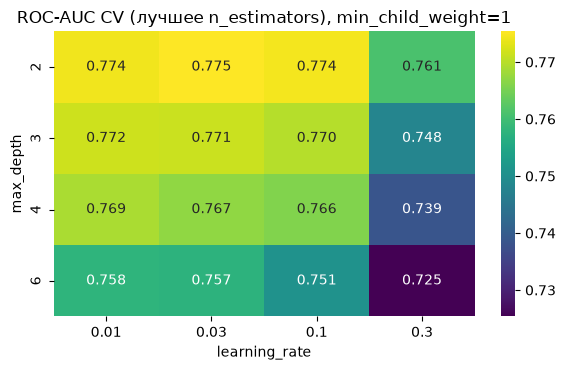

In [5]:
import seaborn as sns
best_mcw = gs.best_params_["xgb__min_child_weight"]
sub = res[res["param_xgb__min_child_weight"] == best_mcw]
heat = sub.groupby(["param_xgb__max_depth", "param_xgb__learning_rate"])["mean_test_score"].max().unstack()
plt.figure(figsize=(6, 3.8))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="viridis")
plt.title(f"ROC-AUC CV (лучшее n_estimators), min_child_weight={best_mcw}")
plt.xlabel("learning_rate"); plt.ylabel("max_depth")
plt.tight_layout(); plt.show()

**Что видно.**

- Лучшие модели все с **неглубокими деревьями** (`max_depth=2`): первые семь мест в таблице. Чем глубже деревья, тем хуже, при `max_depth=6` и `learning_rate=0.3` модель сильно переобучается (худшая комбинация 0,715).
- `learning_rate` и `n_estimators` компенсируют друг друга: 0,01 × 600 деревьев, 0,03 × 300 и 0,1 × 100 дают почти одно и то же (0,774–0,775). Важно произведение «скорость × число деревьев», а не каждый параметр отдельно.
- Различия между лучшими комбинациями (0,7754, 0,7744, 0,7742) намного меньше стандартного отклонения по фолдам (0,013–0,015). Выбрать «самую лучшую» из них можно только условно: на других фолдах порядок мог бы быть другим.

## Веха 12.3. RandomizedSearchCV при сопоставимом бюджете

Случайный поиск берёт параметры из распределений, а не из сетки: `max_depth` от 2 до 6, `learning_rate` логарифмически от 0,01 до 0,3, `n_estimators` от 100 до 600, `min_child_weight` от 1 до 10. Сравниваю два бюджета: 24 комбинации (четверть сетки) и 96 (столько же, сколько у сетки).

In [6]:
dist = {"xgb__max_depth": randint(2, 7),
        "xgb__learning_rate": loguniform(0.01, 0.3),
        "xgb__n_estimators": randint(100, 601),
        "xgb__min_child_weight": randint(1, 11)}
rows = [{"метод": "GridSearchCV", "комбинаций": n_grid, "время, с": grid_sec, "лучший ROC-AUC CV": gs.best_score_}]
searches = {}
for n_iter in [24, n_grid]:
    rs = RandomizedSearchCV(make_pipe(), dist, n_iter=n_iter, cv=cv, scoring="roc_auc",
                            n_jobs=-1, random_state=SEED)
    t0 = time.perf_counter()
    rs.fit(X_train, y_train)
    sec = time.perf_counter() - t0
    searches[n_iter] = rs
    rows.append({"метод": f"RandomizedSearchCV, n_iter={n_iter}", "комбинаций": n_iter,
                 "время, с": sec, "лучший ROC-AUC CV": rs.best_score_})
cmp = pd.DataFrame(rows).set_index("метод")
for n_iter, rs in searches.items():
    p = {k.split("__")[1]: (round(v, 4) if isinstance(v, float) else v) for k, v in rs.best_params_.items()}
    print(f"Random n_iter={n_iter}: {p}")
cmp.round(4)

Random n_iter=24: {'learning_rate': np.float64(0.0105), 'max_depth': 4, 'min_child_weight': 1, 'n_estimators': 491}
Random n_iter=96: {'learning_rate': np.float64(0.0338), 'max_depth': 2, 'min_child_weight': 7, 'n_estimators': 300}


,комбинаций,"время, с",лучший ROC-AUC CV
метод,,,
GridSearchCV,96,5.4807,0.7754
"RandomizedSearchCV, n_iter=24",24,1.2589,0.7693
"RandomizedSearchCV, n_iter=96",96,4.2958,0.7758


**Какой метод лучше.**

- **При одинаковом бюджете** (96 комбинаций) случайный поиск дал чуть **больше** (0,7758 против 0,7754) и чуть **быстрее** (около 4,5 с против 5,5 с у сетки, точное время меняется от запуска к запуску: случайные `n_estimators` в среднем меньше, чем в сетке). Он нашёл почти ту же точку, что и сетка (`max_depth=2`, `learning_rate=0.034`, 300 деревьев), но с `min_child_weight=7`, которого в сетке не было.
- **С четвертью бюджета** (24 комбинации) случайный поиск примерно за 1,3 с нашёл 0,7693: в 4 раза быстрее сетки, проигрыш 0,006, меньше разброса между фолдами.
- Почему так: у сетки на каждый параметр всего 2–4 значения, а случайный поиск пробует каждый раз новые значения всех параметров. Когда важны не все параметры (здесь `min_child_weight` почти не влияет), случайный поиск тратит бюджет эффективнее.

Разница между методами по качеству в пределах шума. Практический вывод: случайный поиск лучше, когда бюджет ограничен и параметров много.

## Веха 12.4. Итоговая модель на отложенном test

Беру лучшую модель сеточного поиска (`refit=True`: GridSearchCV после поиска сам переобучил её на всём train) и **впервые** смотрю на test. Дополнительно повторяю кросс-валидацию тех же параметров на 10 новых разбиениях train на фолды, которые в поиске не использовались.

In [7]:
best = gs.best_estimator_        # GridSearchCV уже переобучил лучшую модель на всём train
best_test = roc_auc_score(y_test, best.predict_proba(X_test)[:, 1])

# «Честная» кросс-валидация лучших параметров на НОВЫХ фолдах (другое перемешивание)
fresh = []
for rs in range(10):
    cv_new = StratifiedKFold(n_splits=5, shuffle=True, random_state=100 + rs)
    fresh.append(cross_val_score(make_pipe(**{k.split("__")[1]: v for k, v in gs.best_params_.items()}),
                                 X_train, y_train, cv=cv_new, scoring="roc_auc").mean())

three = pd.DataFrame({
    "величина": ["лучший результат поиска (best_score_)",
                 "CV тех же параметров на новых фолдах (10 разбиений)",
                 "отложенный test"],
    "ROC-AUC": [gs.best_score_, np.mean(fresh), best_test]}).set_index("величина")
print(f"CV на новых фолдах: среднее {np.mean(fresh):.4f}, от {min(fresh):.4f} до {max(fresh):.4f}")
three.round(4)

CV на новых фолдах: среднее 0.7703, от 0.7634 до 0.7752


,ROC-AUC
величина,
лучший результат поиска (best_score_),0.7754
CV тех же параметров на новых фолдах (10 разбиений),0.7703
отложенный test,0.7945


In [8]:
summary = pd.DataFrame([
    {"модель": "XGBoost до подбора (300, 0.05, 4)", "ROC-AUC CV": base_cv.mean(), "ROC-AUC test": base_test},
    {"модель": "XGBoost после GridSearchCV", "ROC-AUC CV": gs.best_score_, "ROC-AUC test": best_test},
]).set_index("модель")
summary.round(4)

,ROC-AUC CV,ROC-AUC test
модель,,
"XGBoost до подбора (300, 0.05, 4)",0.7600,0.7788
XGBoost после GridSearchCV,0.7754,0.7945


## Веха 12.5. Почему три оценки различаются

In [9]:
# Насколько оценка по одному разбиению зависит от случая: 20 разных разбиений train/val внутри train
single = []
params = {k.split("__")[1]: v for k, v in gs.best_params_.items()}
for rs in range(20):
    a, b, ya, yb = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=rs)
    m = make_pipe(**params).fit(a, ya)
    single.append(roc_auc_score(yb, m.predict_proba(b)[:, 1]))
print(f"одно разбиение 80/20: ROC-AUC от {min(single):.3f} до {max(single):.3f}, std {np.std(single):.3f}")

одно разбиение 80/20: ROC-AUC от 0.743 до 0.794, std 0.015


Три величины:

| Величина | ROC-AUC |
| --- | --- |
| Лучший результат поиска (`best_score_`) | 0,7754 |
| Кросс-валидация тех же параметров на новых фолдах (среднее по 10) | 0,7703 |
| Отложенный test | 0,7945 |

- **`best_score_` завышен.** Это максимум из 96 оценок, каждая из которых содержит случайную ошибку (std по фолдам около 0,014). Выбирая максимум, мы выбираем не только лучшие параметры, но и самую удачную случайную ошибку. На новых фолдах те же параметры дают в среднем 0,7703, на 0,005 меньше: это и есть оптимистичное смещение от выбора максимума.
- **Test выше обеих.** Это не значит, что модель на новых данных работает лучше. Test это одно случайное разбиение из 600 абонентов, а оценка по одному разбиению сильно шумит: на 20 разных разбиениях train 80/20 ROC-AUC тех же параметров был от 0,743 до 0,794 (std 0,015). Значение 0,7945 на test попадает в верхний край этого диапазона, нашему test просто «повезло». Такой же эффект был в ПР-8 и ПР-9: на test модели получали больше, чем на кросс-валидации.
- **Ни одна оценка не «правильная»**: честная оценка качества это 0,77 ± 0,015. Test нужен не ради точного числа, а потому что он **не участвовал в выборе**, и подогнать параметры под него было невозможно. Если бы я подбирал параметры по test, его оценка стала бы так же завышена, как `best_score_`.

## Итог

| Модель | ROC-AUC CV | ROC-AUC test |
| --- | --- | --- |
| XGBoost до подбора (300 деревьев, `learning_rate=0.05`, `max_depth=4`) | 0,760 | 0,779 |
| XGBoost после GridSearchCV (300 деревьев, `learning_rate=0.03`, `max_depth=2`) | 0,775 | 0,795 |

- Подбор гиперпараметров дал прирост около 0,015 и на кросс-валидации, и на test. Главное изменение: деревья глубиной 2 вместо 4, то есть более простая модель, которая меньше переобучается на 2400 абонентах.
- Гиперпараметры подбирались только на train (кросс-валидация), итоговая оценка на test, который в подборе не участвовал. Предобработка внутри пайплайна, кросс-валидация стратифицированная.
- RandomizedSearchCV при том же бюджете нашёл не хуже сетки и быстрее, а с четвертью бюджета проиграл всего 0,006.
- Лучший результат поиска систематически завышен (выбор максимума), а одно разбиение шумит на ±0,015, поэтому сравнивать модели по разнице в третьем знаке бессмысленно.
- Даже после подбора XGBoost (0,795) не лучше логистической регрессии из ПР-8 (0,806 на том же test).